In [2]:
import os
import time
import matplotlib.pyplot as plt

In [3]:
class GameOfLife(object):  
    
    def __init__(self, x_dim, y_dim):
        # For  creating a grid after starting
        self._grid= [[0 for i in range (x_dim)] for j in range (y_dim)]
    
    def get_grid(self):
        return self._grid

    
    def print_grid(self):

        print('='*20 , '\n')
        os.system('cls' if os.name == 'nt' else 'clear')
        
        grid_data= self.get_grid()
        for row in grid_data:
            print(' '.join('■' if cell else '·' for cell in row))
        time.sleep(0.2)
        print('='*20 , '\n')
        
    
    def populate_grid(self, coord):       
        # Makes or keeps a grid cell alive.
        for (x,y) in coord:
            self._grid[x][y]=1
            

    
    def make_step(self):
        # for updating the logic of conway's game  of life.
        grid_data = [[item for item in row] for row in self.get_grid()]  # deepcopy of self._grid
        y_dim = len(grid_data)
        x_dim = len(grid_data[0])

        #We will make a for loop to calculate the alive cells around 1 cell
        alive_nbs=[[0 for k in row] for row in self.get_grid()]  # the alive neighbours of each cell list in the same shape of grid

        # loop to find the sum of neighbours for each cell
        for y in range(y_dim):
            for x in range(x_dim):
                
                x_nbs_index = [x+i for i in (-1 , 0 , 1) if x+i>=0 and x+i< x_dim]
                
                y_nbs_index = [y+i for i in (-1 , 0 , 1) if y+i>=0 and y+i< y_dim]
                
                value_nbs = [grid_data[x_][ y_]for x_ in x_nbs_index for y_ in y_nbs_index if (x_ , y_) != (x,y)]

                alive_nbs_cell = sum(value_nbs)

                alive_nbs[x][y] = alive_nbs_cell

        # updating values depending on sum of alive neighbours
        for y in range(y_dim):
            for x in range (x_dim):

                if self._grid[x][y] :
                    if alive_nbs[x][y] <2 or alive_nbs[x][y]>3:
                        self._grid[x][y] = 0
                    else: continue
    
                else:
                    if alive_nbs[x][y] == 3:
                        self._grid[x][y] = 1
                    else: continue
                    
        self.draw_grid()
  
    def make_n_steps(self, n):
        # Implement a method that applies the make_step method n times.
        for _ in range (n):
            print(f'Step number:  {_+1}')
            self.make_step()

    def draw_grid(self):
        # Draw the current state of the grid.
        grid_data= self.get_grid()
        x_dim = len(grid_data[0])
        y_dim = len(grid_data)
        x_axis=[x for y in range (y_dim) for x in range (x_dim)]
        y_axis=[y for y in range (y_dim) for x in range (x_dim)]

        
        # Matplotlib reads the 2D list directly
        plt.imshow(grid_data)
        plt.show()
        

Enter the width of the grid:  30
Enter the length of the grid:  30


Enter the coordinations of the initial living cells (press  Enter after finished): 


 15 15
 15 16
 15 17
 15 18
 16 18
 16 17
 18 18
 19 18
 17 15
 17 16
 18 19
 
Enter the number of steps (generations you want to make) 15


Step number:  1


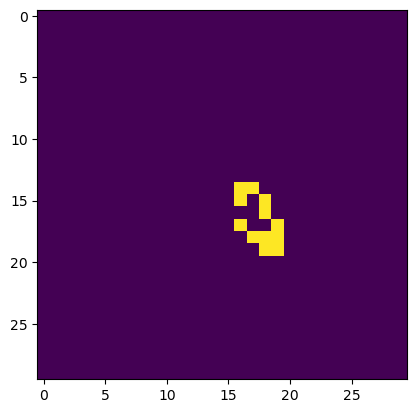

Step number:  2


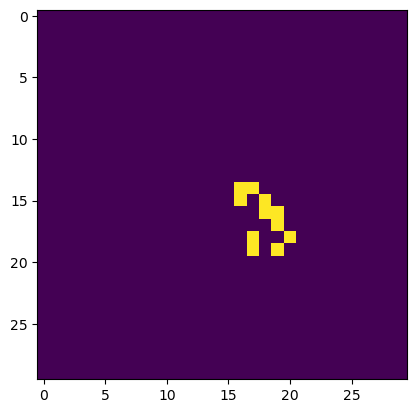

Step number:  3


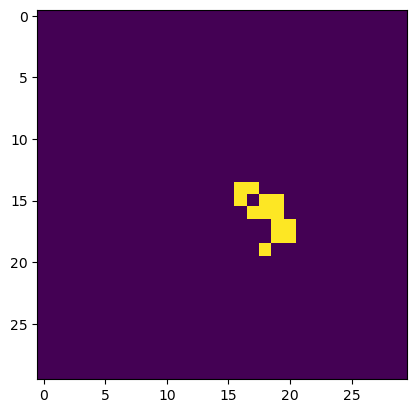

Step number:  4


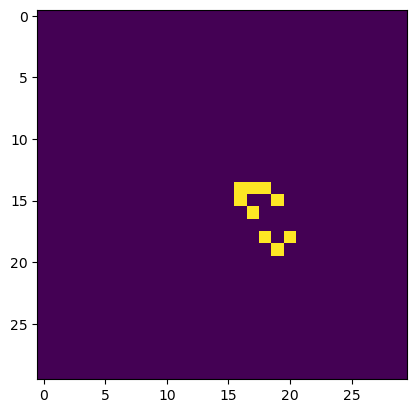

Step number:  5


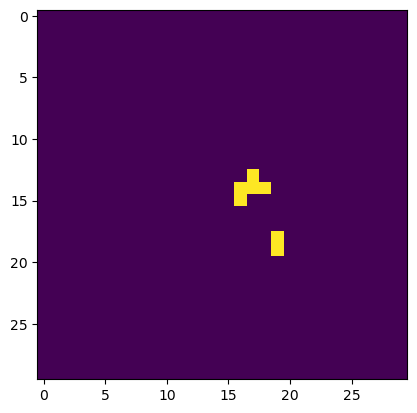

Step number:  6


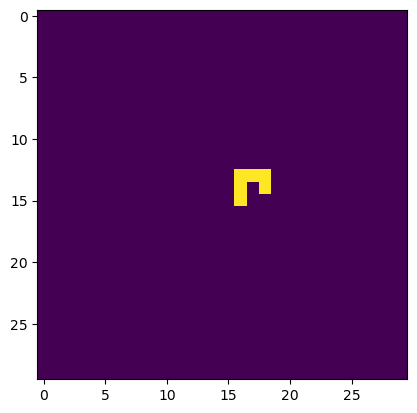

Step number:  7


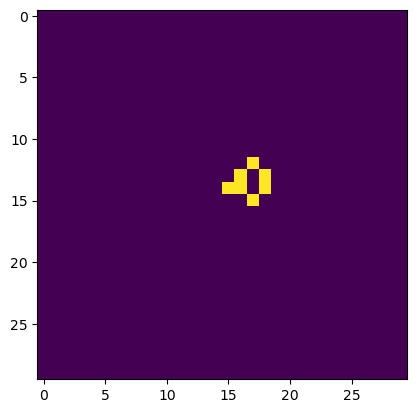

Step number:  8


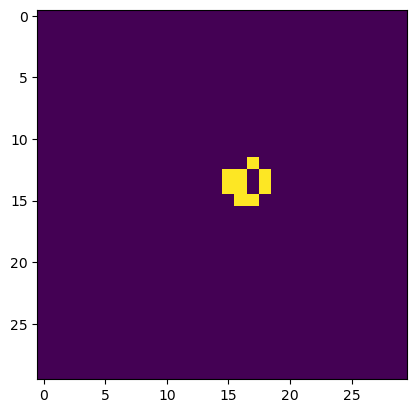

Step number:  9


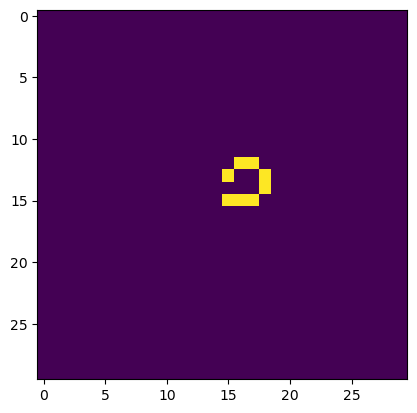

Step number:  10


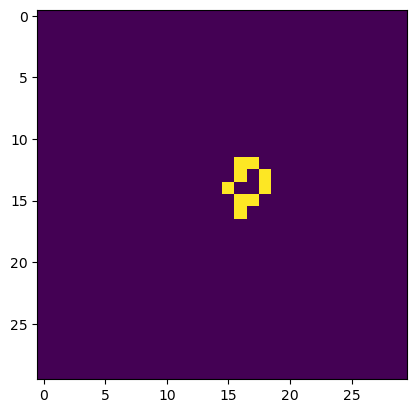

Step number:  11


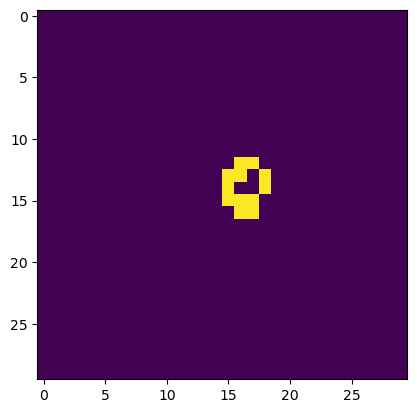

Step number:  12


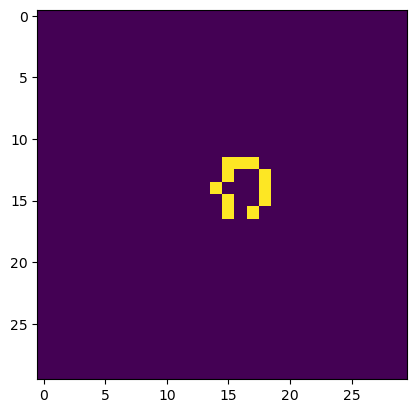

Step number:  13


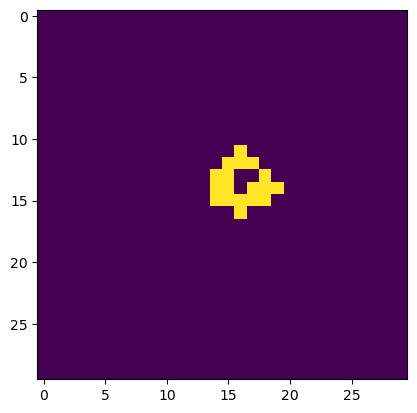

Step number:  14


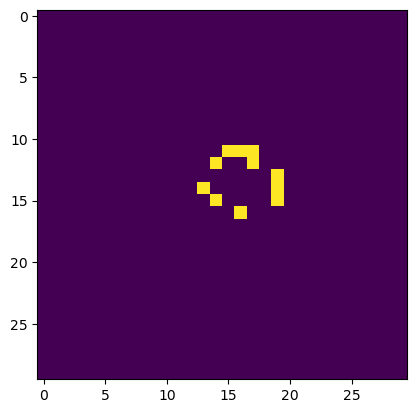

Step number:  15


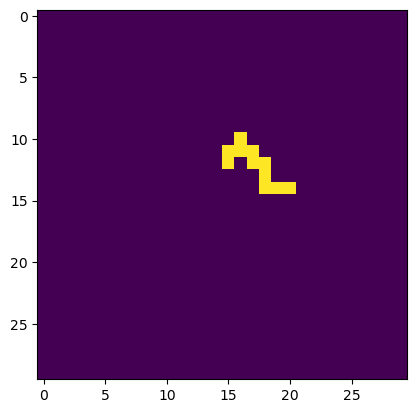

Simulation completed=======================================================


In [26]:
# user interface
x_dim = int(input('Enter the width of the grid: '))
y_dim = int(input('Enter the length of the grid: '))
user_game = GameOfLife(x_dim , y_dim)
print('Enter the coordinations of the initial living cells (press  Enter after finished): ')
living_cells=[]
while (True):
    
    liv_cell = tuple([int(x) for x in input().split(' ') if x.isdigit()])
    
    if len(liv_cell) == 0:
        break

    if len(liv_cell) !=2:
        print('only X and Y coodinations , try again')
        continue

    if liv_cell[0]>=x_dim or liv_cell[1] >=y_dim or liv_cell[0] <0 or liv_cell[1] <0:
        print('This cell is out  of borders , try again')
        continue
    living_cells .append(liv_cell)
    
user_game.populate_grid(living_cells)
steps=int(input ('Enter the number of steps (generations you want to make)'))
user_game.make_n_steps(steps)
print('Simulation completed=======================================================')


Step number:  1


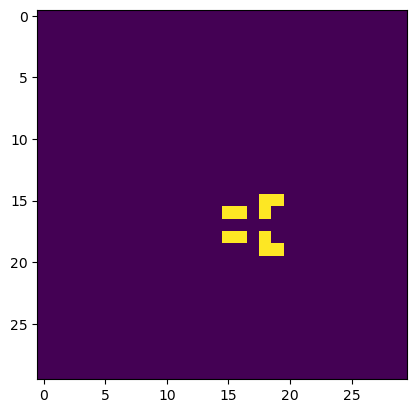

Step number:  2


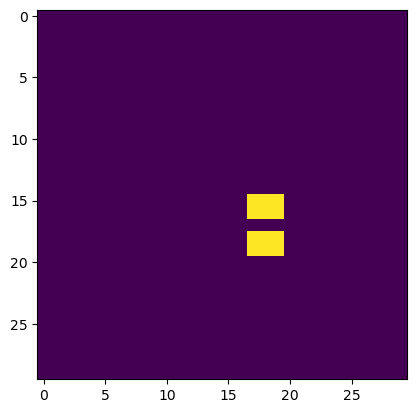

Step number:  3


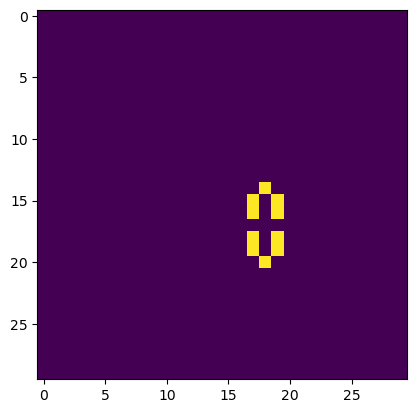

Step number:  4


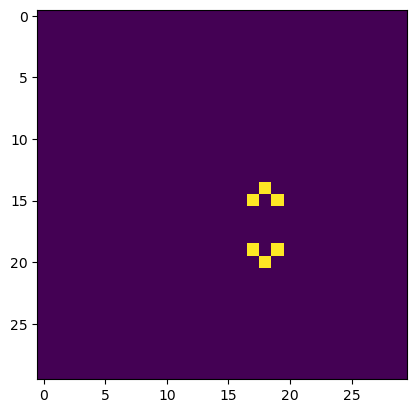

Step number:  5


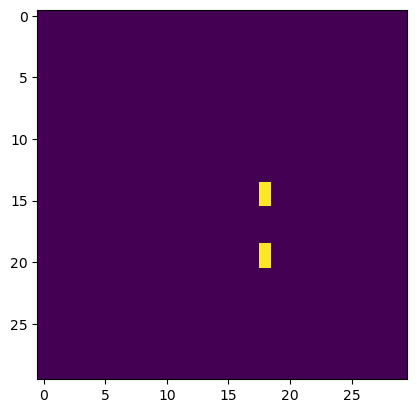

Step number:  6


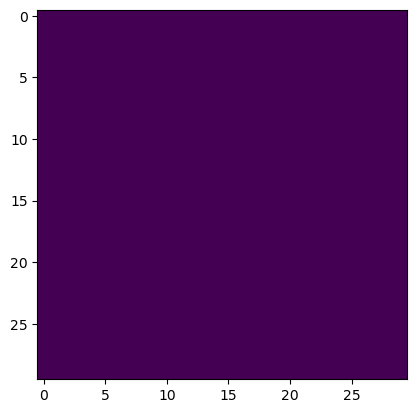

Step number:  7


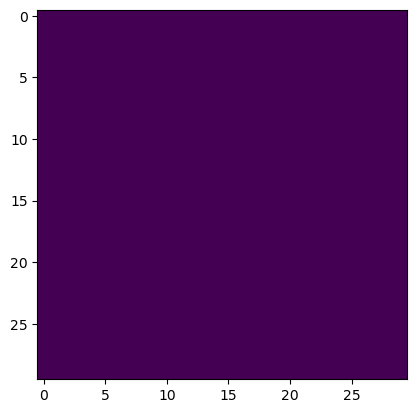

Step number:  8


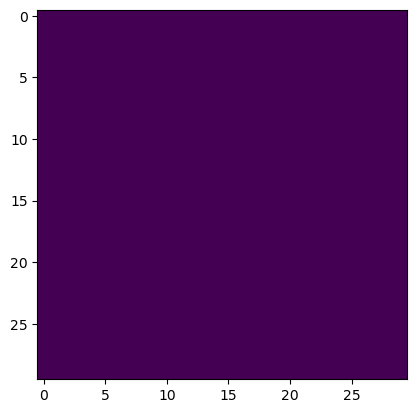

Step number:  9


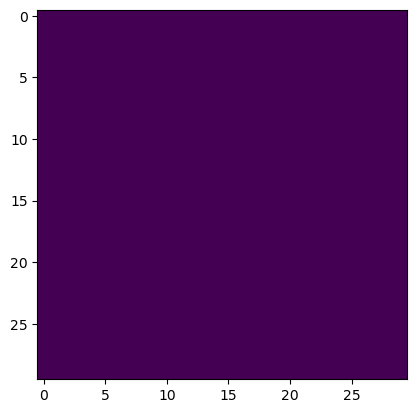

Step number:  10


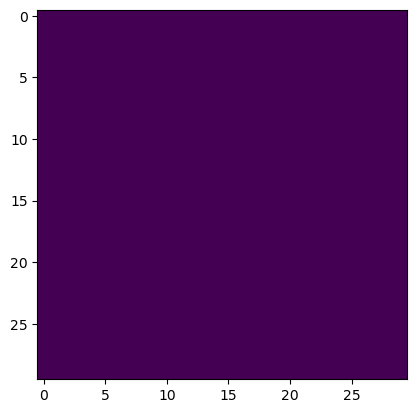

Step number:  11


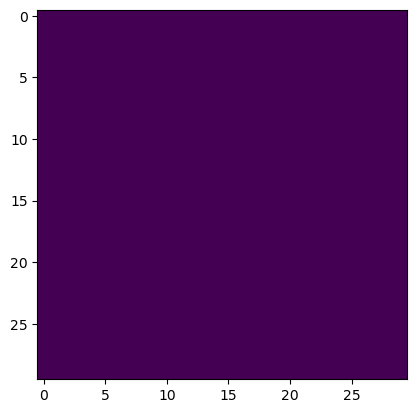

Step number:  12


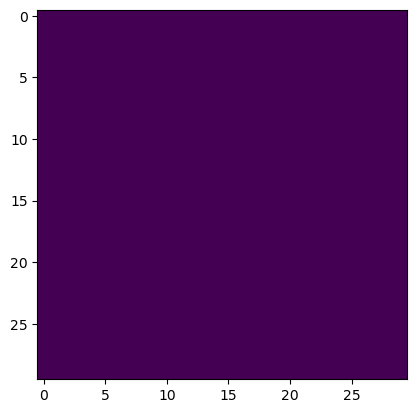

In [27]:
# test area
test=GameOfLife(30,30)
test.populate_grid([(14, 16), (15, 16), (16, 16), (18, 16), (19, 16), (20, 16),
(16, 14), (16, 15), (16, 17), (16, 18),
(18, 14), (18, 15), (18, 17), (18, 18),
(14, 18), (15, 18), (16, 18), (18, 18), (19, 18), (20, 18)])
test.make_n_steps(12)

[1, 3]